#### Results. Section #1
##### Developmental programs define a low-dimensional reference subspace that only partially constrains malignant state


>Libraries

In [6]:
import os,json
import numpy as np
import pandas as pd   # dataframes
import matplotlib.pyplot as plt

from pprint import pprint

import scanpy as sc

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from scipy.stats import gaussian_kde
from scipy.stats import ttest_ind

import torch
from transformers import BertForMaskedLM

In [7]:
# adjust you own path
commonpath = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/"
saved_dir = os.path.join(commonpath,"models/bert_dev_learned/")

>Learned model

In [8]:
# loads a pretrained BERT model for masked language modeling
# config.json defines the model architecture and settings
# model.safetensors contains the trained weights
model = BertForMaskedLM.from_pretrained(saved_dir)

meta_path = os.path.join(saved_dir, "vocab_meta.json")
with open(meta_path) as f:
    meta = json.load(f)

# Meta is a dictionary with the following keys
print('keys of meta dictionary -> ',meta.keys())

# some checking
required = ["gene2id","PAD_ID","CLS_ID","SEP_ID","MASK_ID","DEV_DOM_ID","CANCER_DOM_ID","vocab_size"]
missing = [k for k in required if k not in meta]
assert not missing, f"vocab_meta.json missing keys: {missing}"

# unpacking the dictionary into variables.
gene2id       = meta["gene2id"]
PAD_ID        = meta["PAD_ID"]
CLS_ID        = meta["CLS_ID"]
SEP_ID        = meta["SEP_ID"]
MASK_ID       = meta["MASK_ID"]
DEV_DOM_ID    = meta["DEV_DOM_ID"]
CANCER_DOM_ID = meta["CANCER_DOM_ID"]
vocab_size    = meta["vocab_size"]

# Sanity checks (fail fast)
assert model.config.vocab_size == vocab_size, (
    f"Model vocab_size ({model.config.vocab_size}) != meta vocab_size ({vocab_size}). "
    "You likely loaded mismatched checkpoint + vocab."
)

# Ensure special IDs are in range and distinct (no two special tokens share the same ID)
specials = [PAD_ID, CLS_ID, SEP_ID, MASK_ID, DEV_DOM_ID, CANCER_DOM_ID]
assert len(set(specials)) == len(specials), "Some special token IDs collide."
assert all(0 <= x < vocab_size for x in specials), "A special token ID is out of vocab range."

keys of meta dictionary ->  dict_keys(['gene2id', 'PAD_ID', 'CLS_ID', 'SEP_ID', 'MASK_ID', 'DEV_DOM_ID', 'CANCER_DOM_ID', 'vocab_size'])


In [9]:
pprint(model.config.to_dict())

{'_name_or_path': '/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/models/bert_dev_learned/',
 'add_cross_attention': False,
 'architectures': ['BertForMaskedLM'],
 'attention_probs_dropout_prob': 0.1,
 'bad_words_ids': None,
 'begin_suppress_tokens': None,
 'bos_token_id': None,
 'chunk_size_feed_forward': 0,
 'classifier_dropout': None,
 'cross_attention_hidden_size': None,
 'decoder_start_token_id': None,
 'diversity_penalty': 0.0,
 'do_sample': False,
 'dtype': 'float32',
 'early_stopping': False,
 'encoder_no_repeat_ngram_size': 0,
 'eos_token_id': None,
 'exponential_decay_length_penalty': None,
 'finetuning_task': None,
 'forced_bos_token_id': None,
 'forced_eos_token_id': None,
 'hidden_act': 'gelu',
 'hidden_dropout_prob': 0.1,
 'hidden_size': 256,
 'id2label': {0: 'LABEL_0', 1: 'LABEL_1'},
 'initializer_range': 0.02,
 'intermediate_size': 512,
 'is_decoder': False,
 'is_encoder_decoder': False,
 'label2id': {'LABEL_0': 0, 'LABEL_1': 1},
 'layer_norm_eps': 1e-12,
 'l

In [10]:
print("vocab_size:", model.config.vocab_size)
print("number_gen:", len(gene2id))

vocab_size: 15382
number_gen: 15376


In [11]:
X_tokens_eval = np.load(os.path.join(saved_dir, "X_tokens.npy"))
X_attn_eval   = np.load(os.path.join(saved_dir, "X_attn.npy"))
domain_eval   = np.load(os.path.join(saved_dir, "domain.npy"))

In [13]:
# For each cell, tokens are: [DOM] + [CLS] + K genes + [SEP]; K = 128
print(X_tokens_eval.shape)
print(X_attn_eval.shape)
print(domain_eval.shape)

(62891, 131)
(62891, 131)
(62891,)


>Define CLS embeddings

This function produces one vector per cell that summarizes the **entire** cell’s tokenized gene-expression sequence.\
This summary vector is the classification-token, or CLS, *embedding*.

**Why CLS?**
- BERT uses the CLS token to store a compressed representation of the whole input sequence.
- We exploit this to get a *single* vector representing each cell.

In [14]:
# This disables gradient tracking. You’re doing inference, not training. Saves memory
@torch.no_grad()

def cls_embeddings(model, Xt, At, batch_size=16):
    """
    Compute CLS embeddings for a set of tokenized cells.

    Xt: numpy array of shape (N, L) with token IDs
    At: numpy array of shape (N, L) with attention masks
    batch_size: how many cells to process at once (for memory reasons)

    Returns:
      CLS: numpy array of shape (N, H)
           where H = hidden size of the BERT model.
           Each row is the CLS embedding for one cell.
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    # Why eval() matters: Disables dropout. Makes outputs deterministic
    # Dropout. During training, the model randomly “ignores” some neurons each time it processes input.
    model.eval() 

    embs = []

    N = Xt.shape[0]
    for i in range(0, N, batch_size):
        # Take a minibatch of cells, B
        x_batch = Xt[i:i+batch_size]
        a_batch = At[i:i+batch_size]

        # Convert to torch tensors on the right device
        x = torch.as_tensor(x_batch, dtype=torch.long, device=device)  # (B, L)
        a = torch.as_tensor(a_batch, dtype=torch.long, device=device)  # (B, L)

        # Run only the BERT encoder
        out = model.bert(input_ids=x,attention_mask=a,output_hidden_states=False,return_dict=True)

        # out.last_hidden_state: (B, L, H)
        # Your sequence is [DOM], [CLS], genes..., [SEP],
        # so CLS is at position index 1.
        cls_batch = out.last_hidden_state[:, 1, :]   # (B, H)

        # Move to CPU and store
        embs.append(cls_batch.cpu())

    # Concatenate all batches -> (N, H)
    CLS = torch.cat(embs, dim=0).numpy()
    return CLS

In [15]:
# Compute CLS embeddings for eval set 
CLS = cls_embeddings(model, X_tokens_eval, X_attn_eval, batch_size=16)  # (N, H)

# domain_eval: 0 = development, 1 = cancer
is_dev = (domain_eval == 0)
is_can = (domain_eval == 1)

In [16]:
# .. specific of each domain
X_dev = CLS[is_dev]   # (n_dev, H)
X_can = CLS[is_can]   # (n_can, H)
del CLS

print("X_dev:", X_dev.shape)
print("X_can:", X_can.shape)

X_dev: (34760, 256)
X_can: (28131, 256)


>Developmental subspace analysis and cancer projection

In [17]:
def dev_subspace_analysis(X_dev, X_can, k=30):
    # k is the number of principal components
    
    # Center using DEV mean
    mu = X_dev.mean(axis=0)
    Xd = X_dev - mu
    Xc = X_can - mu

    # PCA on DEV only
    pca = PCA(n_components=k)
    pca.fit(Xd)

    basis = pca.components_.T   # this is the matrix U, dims (H, k)

    # Project cancer into DEV-PC subspace
    can_proj = Xc @ basis
    
    can_recon = can_proj @ basis.T
    proj_norm = np.linalg.norm(can_recon, axis=1)
    
    can_residual = Xc - can_recon
    residual_norm = np.linalg.norm(can_residual, axis=1)
    
    per_cell_score = (proj_norm**2) / (proj_norm**2 + residual_norm**2 + 1e-12)
    
    total_var = np.mean(np.sum(Xc**2, axis=1))
    proj_var  = np.mean(np.sum(can_recon**2, axis=1))
    explained_fraction = proj_var / total_var
    
    return {
        "explained_fraction": explained_fraction,
        "residual_norm": residual_norm,
        "projection_score": per_cell_score,
    }

In [ ]:
# .. Example for default k = 30
out = dev_subspace_analysis(X_dev, X_can)
print("Explained variance fraction:", out["explained_fraction"])
print("Mean projection score:", out["projection_score"].mean())

Explained variance fraction: 0.15035716
Mean projection score: 0.15018362


In [19]:
# .. range of PCs
for k in [10, 20, 30, 50, 75,90, 150]:
    out = dev_subspace_analysis(X_dev, X_can, k=k)
    print("Components",k, "- variance explained: ",out["explained_fraction"])


Components 10 - variance explained:  0.029249473
Components 20 - variance explained:  0.07165022
Components 30 - variance explained:  0.15035716
Components 50 - variance explained:  0.28319076
Components 75 - variance explained:  0.4042338
Components 90 - variance explained:  0.5017005
Components 150 - variance explained:  0.8048018


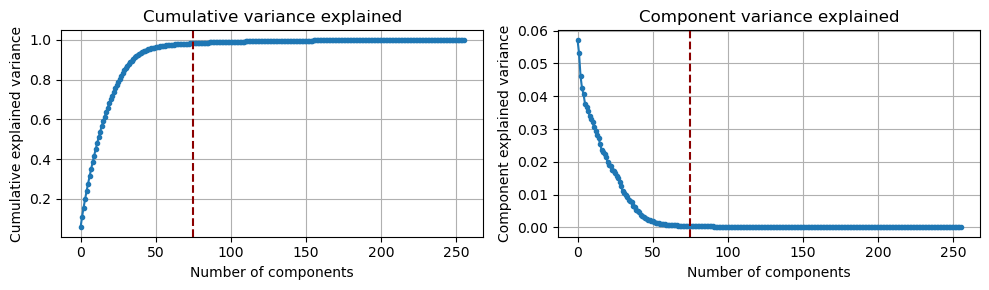

DEV variance explained by first 75 PCs: 0.981794


In [21]:
# .. how much developmental variation is explained by the first PCs
pca_full = PCA().fit(X_dev - X_dev.mean(axis=0))

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=False)

# left: cumulative explained variance
axes[0].plot(cum_var, marker='.')
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("Cumulative variance explained")
axes[0].axvline(75, linestyle='--', color="darkred")
axes[0].grid()

# right: per-component explained variance
axes[1].plot(pca_full.explained_variance_ratio_, marker='.')
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Component explained variance")
axes[1].set_title("Component variance explained")
axes[1].axvline(75, linestyle='--', color="darkred")
axes[1].grid()

plt.tight_layout()
plt.show()

print("DEV variance explained by first 75 PCs:",
      pca_full.explained_variance_ratio_[:75].sum())


Even at 75 developmental PCs, where development is almost fully captured, cancer lives only 40% inside the corresponding subspace. That is not “reuse.” **Cancer occupies a largely orthogonal geometric regime.** This is exactly the structural claim to test.

In [22]:
print("recall embedding dimension =",X_dev.shape[1])

recall embedding dimension = 256


Some further checks on the correctness of the geometric argument: Norm comparison

In [23]:
print("Mean norm DEV:", np.linalg.norm(X_dev, axis=1).mean())
print("Mean norm CAN:", np.linalg.norm(X_can, axis=1).mean())

Mean norm DEV: 15.504947
Mean norm CAN: 15.511465


DEV std: 0.06923051
CAN std: 0.054302104


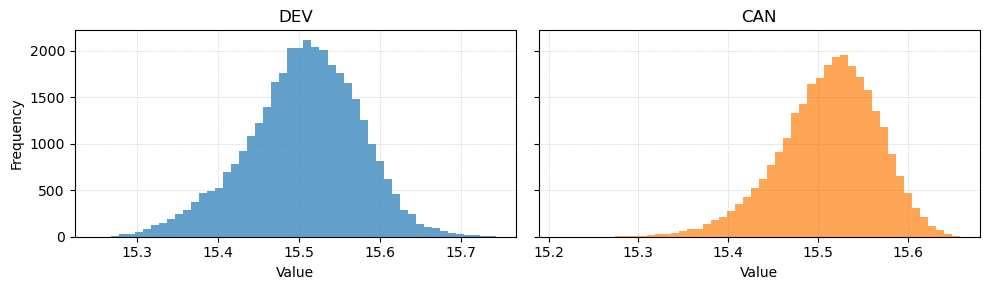

In [25]:
dev_norms = np.linalg.norm(X_dev, axis=1)
can_norms = np.linalg.norm(X_can, axis=1)

print("DEV std:", dev_norms.std())
print("CAN std:", can_norms.std())

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

axes[0].hist(dev_norms, bins=50, alpha=0.7, color='C0')
axes[0].set_title('DEV')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, linestyle=':', linewidth=0.5, color='gray', alpha=0.6)

axes[1].hist(can_norms, bins=50, alpha=0.7, color='C1')
axes[1].set_title('CAN')
axes[1].set_xlabel('Value')
axes[1].grid(True, linestyle=':', linewidth=0.5, color='gray', alpha=0.6)

plt.tight_layout()
plt.show()

In [26]:
# .. are these distributions different?
print(ttest_ind(dev_norms, can_norms))

# .. how big the difference is, between the distributions, in units of “typical variation.”
d = (dev_norms.mean() - can_norms.mean()) / np.sqrt(
    (dev_norms.std()**2 + can_norms.std()**2) / 2
)
print("Cohen's d:", d)

TtestResult(statistic=-12.90283291494999, pvalue=4.849290629770105e-38, df=62889.0)
Cohen's d: -0.10477043270566358


H = 256, so 75 PCs is ~29% of dimensions.
 - DEV is 98.18% explained by its first 75 PCs → development is very low-dimensional in this space.
 - DEV and CAN norms are identical → no trivial scale inflation.

Cancer is largely outside the developmental subspace
- At k=75 (where DEV ≈ 98% captured), cancer still only has 40.4% of its variance in that same subspace.

The structural claim:
- In the learned embedding space, developmental programs lie on a low-dimensional manifold; malignant states are not confined to it and contain a large orthogonal component.

Quantitatively:
- DEV is ~98% contained in a 75D subspace (of 256D).
- Cancer has only ~40% of its variance in that same subspace.
- Therefore **~60% of cancer variance lies in directions that are not used by development** (as represented by this model and data).

**Figures to Fig 1**

In [28]:
k_chosen = 75
out = dev_subspace_analysis(X_dev, X_can, k = k_chosen)
orth_frac = 1.0 - out["explained_fraction"]  # or compute from your out dict
print("Orthogonal variance fraction:", orth_frac)

Orthogonal variance fraction: 0.5957661867141724


Per-cell projection score distributions\
with development as control (this should be scores~1)

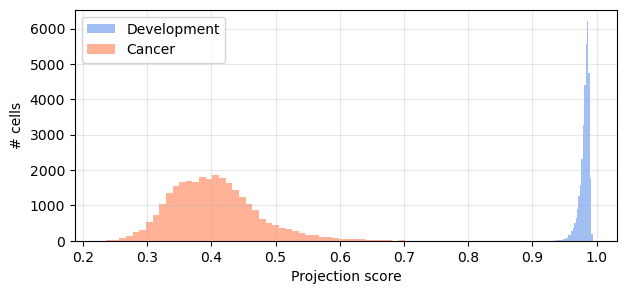

DEV median score: 0.9833385
CAN median score: 0.39868492
Projection score quantiles cancer: [0.27832299 0.30968657 0.32665586 0.39868492 0.48951146 0.52625912
 0.60365102]


In [29]:
scores = out["projection_score"]

out_devctrl = dev_subspace_analysis(X_dev, X_dev, k=k_chosen)
scores_dev = out_devctrl["projection_score"]

plt.figure(figsize=(7,3))
plt.hist(scores_dev, bins=60, alpha=0.6, color = "cornflowerblue",label="Development")
plt.hist(scores,     bins=60, alpha=0.6, color = "coral",label="Cancer")
plt.xlabel("Projection score")
plt.ylabel("# cells")
#plt.title(f"Development vs. Cancer projection score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("DEV median score:", np.median(scores_dev))
print("CAN median score:", np.median(scores))

print("Projection score quantiles cancer:",
      np.quantile(scores, [0.01, 0.05, 0.1, 0.5, 0.9, 0.95, 0.99]))

What I just showed

DEV manifold:
- 75 PCs explain 98% of DEV variance.
- DEV median projection score ≈ 0.98
→ as expected, DEV lies almost entirely inside its *own* subspace.

Cancer relative to DEV subspace:
- Only 40% of cancer variance lies inside developmental subspace.
- ~60% is orthogonal.

Cancer median projection score ≈ 0.40, Even 90th percentile ≈ 0.49, 99th percentile ≈ 0.60\
This means: **Most cancer cells are predominantly outside the developmental manifold**.
 
Not a small subset. Not a tail. Not a rare branch. *The bulk of cancer geometry is orthogonal*.

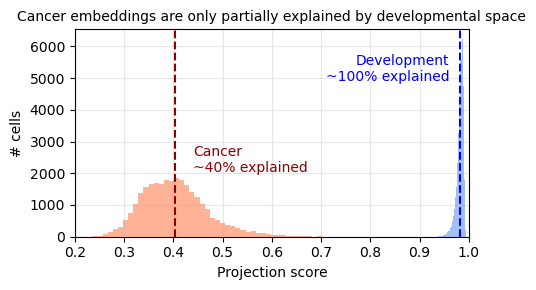

In [30]:
mean_dev = np.mean(scores_dev)
mean_can = np.mean(scores)

plt.figure(figsize=(5,3))

# Your original histograms (kept as-is)
plt.hist(scores_dev, bins=60, alpha=0.6, color = "cornflowerblue",label="Development")
plt.hist(scores,     bins=60, alpha=0.6, color = "coral",label="Cancer")

# Mean lines (key addition)
plt.axvline(mean_dev, color="blue", linestyle="--", linewidth=1.5)
plt.axvline(mean_can, color="darkred", linestyle="--", linewidth=1.5)

# Labels
plt.xlabel("Projection score")
plt.ylabel("# cells")
#plt.legend(frameon=False)
plt.grid(True, alpha=0.3)

# Main message as title
plt.title("Cancer embeddings are only partially explained by developmental space", fontsize=10)

# Clean annotations (relative to axes → no overlap mess)
plt.text(0.95, 0.88, "Development\n~100% explained",
         color="blue", ha="right", va="top",
         transform=plt.gca().transAxes, fontsize=10)

plt.text(0.30, 0.37, "Cancer\n~40% explained",
         color="darkred", ha="left", va="center",
         transform=plt.gca().transAxes, fontsize=10)

# Focus the x-range
plt.xlim(0.2, 1)

plt.tight_layout()
plt.show()

>Is the (cancer) orthogonal space coherent?

In [31]:
# recompute the residuals
# Center on DEV mean
mu = X_dev.mean(axis=0)
Xd = X_dev - mu
Xc = X_can - mu
del X_dev, X_can

# PCA on DEV
pca = PCA(n_components=k_chosen)
pca.fit(Xd)

basis = pca.components_.T  # (256, k)

# Project cancer into DEV subspace
can_proj = Xc @ basis
can_recon = can_proj @ basis.T

# Orthogonal residual
residual = Xc - can_recon


In [ ]:
# Checking residual @ basis tests whether any component of the residual lies along the basis vectors
print('residual shape ->',residual.shape)  # should be (number of cancer cells, embedding dimension)
print('orthogonality check ->',np.max(np.abs(residual @ basis)))

residual shape -> (28131, 256)
orthogonality check -> 4.39398e-06


**test whether the orthogonal component is structured**

how much structured signal is left in your residuals by running PCA on them and measuring how much variance the top PCs capture.

In [32]:
# Center residuals
# substract the average residual vector across all cells
residual_centered = residual - residual.mean(axis=0) # axis 0: down to rows

pca_res = PCA().fit(residual_centered)

print("Residual variance explained by first 10 PCs:",
      pca_res.explained_variance_ratio_[:10].sum())

print("Residual variance explained by first 30 PCs:",
      pca_res.explained_variance_ratio_[:30].sum())

print("Residual variance explained by first 75 PCs:",
      pca_res.explained_variance_ratio_[:75].sum())

Residual variance explained by first 10 PCs: 0.67201215
Residual variance explained by first 30 PCs: 0.8766998
Residual variance explained by first 75 PCs: 0.9763908


Development
- 75 PCs → 98% variance, Low-dimensional manifold.

Cancer inside DEV subspace
- Only 40% variance captured, ~60% orthogonal.

Orthogonal cancer component
- 10 PCs → 67%, **30 PCs → 88%**, 75 PCs → 97%

That means: The orthogonal component is highly structured and low-dimensional.

In [33]:
# Coordinates in developmental space
dev_coords = can_proj  # already computed (n_can, 75)

# Coordinates in malignant residual space
res_coords = pca_res.transform(residual_centered)

print(dev_coords.shape, res_coords.shape)

(28131, 75) (28131, 256)


**Figures to Fig 1**

reload the original aln dataset to get labels

In [34]:
commonpath

'/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/'

In [35]:
# Paths defined at the beginning
in_cancer = os.path.join(commonpath, "pdac/A_cancer_aligned.h5ad")
A_cancer_aln = sc.read_h5ad(in_cancer)

#in_dev    = os.path.join(commonpath, "development/A_dev_aligned.h5ad")
#A_dev_aln    = sc.read_h5ad(in_dev)

labels = A_cancer_aln.obs["cancer_state"].values
labels2 = A_cancer_aln.obs["condition"].values

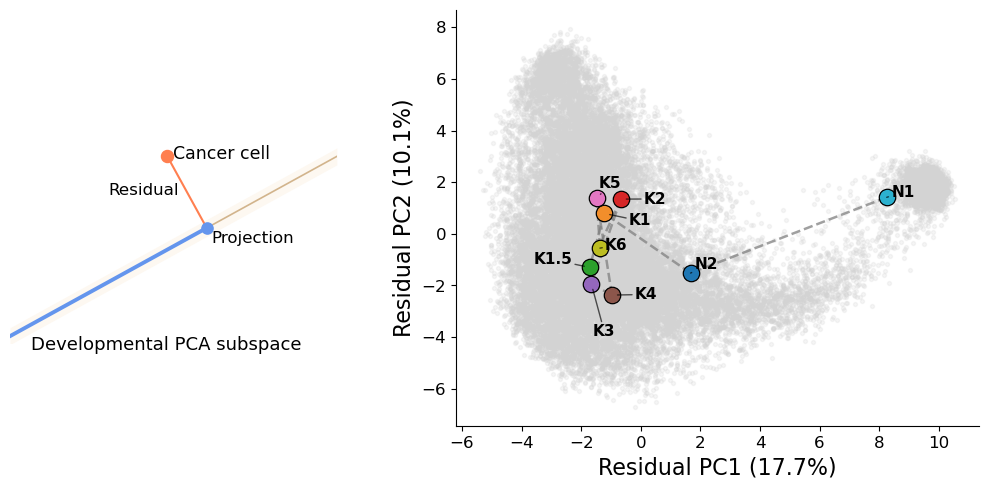

In [36]:
# Build dataframe for panel B
df_plot = pd.DataFrame({"RPC1": res_coords[:, 0],"RPC2": res_coords[:, 1],"condition": labels2})
order = ["N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"]
order_present = [x for x in order if x in df_plot["condition"].unique()]

# distinct centroid colors only
centroid_colors = {"N1": "#2CB1CF","N2": "#1F77B4","K1": "#F28E2B","K1.5": "#2CA02C","K2": "#D62728","K3": "#9467BD",
                   "K4": "#8C564B","K5": "#E377C2","K6": "#BCBD22",}

# =========================
# Create 2-panel figure
# =========================
fig = plt.figure(figsize=(12.5, 5.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.6], wspace=0.28)

# ==========================================================
# PANEL A: schematic of orthogonal decomposition
# ==========================================================
axA = fig.add_subplot(gs[0, 0])

# --- Developmental subspace ---
m = 0.55
b = -0.35

x = np.linspace(-2.6, 2.8, 300)
y = m * x + b
band_halfwidth = 0.14

# light band for developmental subspace
axA.fill_between(x,y - band_halfwidth,y + band_halfwidth,color="antiquewhite",alpha=0.35,linewidth=0,zorder=0)


# --- Projection point on developmental subspace ---
proj_x = 0.65
proj = np.array([proj_x, m * proj_x + b])

# unit vector along subspace
u = np.array([1.0, m])
u = u / np.linalg.norm(u)

# unit vector perpendicular to subspace
n = np.array([-u[1], u[0]])

# cancer cell offset orthogonally from the projection
residual_len = 1.35
cell = proj + residual_len * n

# central developmental axis
axA.plot(x, y, lw=1.2, color = "tan", zorder=1)


# developmental component starts from lower-left on subspace
origin_x = -1.85
origin = np.array([origin_x, m * origin_x + b])

# developmental component 
axA.plot([x[0], proj[0]],[y[0], proj[1]],lw=2.8,color="cornflowerblue",zorder=2)

# non-developmental component
axA.plot([proj[0], cell[0]],[proj[1], cell[1]],lw=1.5,color="coral",zorder=3)

# points
axA.scatter(*proj, s=65, color= "cornflowerblue", zorder=5)
axA.scatter(*cell, s=75, color="coral", zorder=6)

# labels
axA.text(cell[0] + 0.10, cell[1] + 0.04,"Cancer cell",fontsize=12.5, va="center")

axA.text(proj[0] + 0.08, proj[1] - 0.18,"Projection",fontsize=12, va="center")

mid_res = (proj + cell) / 2
axA.text(mid_res[0] - 1.3, mid_res[1] + 0.03,"Residual",fontsize=12, va="center")

axA.text(-2.25, m * (-2.25) + b - 0.42,"Developmental PCA subspace",fontsize=13)

# styling
axA.set_xlim(-2.6, 2.8)
axA.set_ylim(-1.9, 2.25)
axA.set_xticks([])
axA.set_yticks([])
for spine in axA.spines.values():
    spine.set_visible(False)
axA.set_aspect("equal")

# ==========================================================
# PANEL B: residual PCA with grey background + colored centroids
# ==========================================================
axB = fig.add_subplot(gs[0, 1])

# grey background points
axB.scatter(df_plot["RPC1"],df_plot["RPC2"],s=8,color="lightgrey",alpha=0.22,rasterized=True)

# centroids
centroids = []
for cond in order_present:
    sub = df_plot[df_plot["condition"] == cond]
    cx = sub["RPC1"].mean()
    cy = sub["RPC2"].mean()
    centroids.append((cond, cx, cy))

# subtle dashed connections in biological order
for i in range(len(centroids) - 1):
    _, x1, y1 = centroids[i]
    _, x2, y2 = centroids[i + 1]
    axB.plot(
        [x1, x2], [y1, y2],
        ls="--", lw=1.8, color="gray", alpha=0.75, zorder=2
    )

# plot centroids
for cond, cx, cy in centroids:
    c = centroid_colors.get(cond, "black")
    axB.scatter(cx, cy,s=140,color=c,edgecolor="black",linewidth=0.9,zorder=5)

# manual text positions for decluttering
label_pos = {
    "N1": (8.4, 1.6),
    "N2": (1.8, -1.2),
    "K1": (-0.4, 0.5),
    "K1.5": (-3.6, -1.0),
    "K2": (0.1, 1.35),
    "K3": (-1.6, -3.8),
    "K4": (-0.2, -2.35),
    "K5": (-1.4, 1.95),
    "K6": (-1.2, -0.45),
}

for cond, cx, cy in centroids:
    tx, ty = label_pos[cond]
    axB.annotate(
        cond,
        xy=(cx, cy),
        xytext=(tx, ty),
        fontsize=11,
        weight="bold",
        ha="left",
        va="center",
        arrowprops=dict(
            arrowstyle="-",
            lw=1.0,
            color="black",
            alpha=0.65,
            shrinkA=0,
            shrinkB=4
        ),
        zorder=6
    )

#axB.set_title("Residual PCA", fontsize=20)
axB.set_xlabel("Residual PC1 (17.7%)", fontsize=16)
axB.set_ylabel("Residual PC2 (10.1%)", fontsize=16)

axB.spines["top"].set_visible(False)
axB.spines["right"].set_visible(False)
axB.tick_params(labelsize=12)
#axB.text(-0.08, 1.02, "B)", transform=axB.transAxes, fontsize=20, fontweight="normal")

#plt.tight_layout()
plt.show()

>Predictions

**DEV space prediction.**
Use the developmental coordinates (can_proj).

In [37]:
print(labels.categories)
print(labels2.categories)

Index(['ductal', 'malignant_ductal', 'transitional'], dtype='object')
Index(['K1', 'K1.5', 'K2', 'K3', 'K4', 'K5', 'K6', 'N1', 'N2'], dtype='object')


In [38]:
# .. cross validation:
# The dataset is divided into a specified number of folds (subsets, here cv=5). 
# The model is trained on some folds and tested on the remaining fold. 
# clf: The logistic regression model defined below is passed in as the first argument.

#  A feature set (input data, e.g., X_resspace:) that you want to train and validate the model on. 
# It should be a 2D array-like structure where rows represent samples and columns represent features.
# labels: This array contains the target variable (output) corresponding to the feature set, 
# indicating the class labels for classification tasks.

clf = LogisticRegression(max_iter=2000)

X_devspace = can_proj[:, :30]   # first 30 DEV PCs

scores_dev = cross_val_score(clf, X_devspace, labels, cv=5)
scores_dev2 = cross_val_score(clf, X_devspace, labels2, cv=5)

print("DEV-space accuracy:", scores_dev.mean(), "+/-", scores_dev.std())

DEV-space accuracy: 0.9350540039450996 +/- 0.009291192758776367


**RES space prediction.** Now use the malignant residual PCs.

In [39]:
X_resspace = res_coords[:, :30]   # first 30 residual PCs

scores_res = cross_val_score(clf, X_resspace, labels, cv=5)
scores_res2 = cross_val_score(clf, X_resspace, labels2, cv=5)

print("RES-space accuracy:", scores_res.mean(), "+/-", scores_res.std())
print("RES-space accuracy (condition):", scores_res2.mean(), "+/-", scores_res2.std())

RES-space accuracy: 0.9441546398701958 +/- 0.01631660133100652
RES-space accuracy (condition): 0.7253928563283357 +/- 0.021166929621046188


**Combined space** (optional but informative)

In [40]:
X_combined = np.hstack([can_proj[:, :30], res_coords[:, :30]])

scores_combined = cross_val_score(clf, X_combined, labels, cv=5)
scores_combined2 = cross_val_score(clf, X_combined, labels2, cv=5)

print("Combined accuracy:", scores_combined.mean(), "+/-", scores_combined.std())
print("Combined accuracy (condition):", scores_combined2.mean(), "+/-", scores_combined2.std())

Combined accuracy: 0.9558499277675162 +/- 0.015833139844958835
Combined accuracy (condition): 0.7540087275363672 +/- 0.01888056774450471
